---
# **Fairness in Practice: Measuring and Mitigating Bias with AIF360**
*Sustainable Software Engineering — Guest lecture on Fairness*

---

In the first part of the lecture we discussed **what** fairness is, **why** ML systems become unfair, and **which metrics** we can use to talk about it.
In this notebook we get our hands dirty. We take a realistic decision-making problem, **approving or rejecting loan applications**, and we ask
two very concrete engineering questions:

1. **How do we measure** whether a model treats different groups of people fairly?
2. **How do we mitigate** the bias we find, and **what does it cost** us (in accuracy, in computation, in requirements)?

We will use **[AIF360 (AI Fairness 360)](https://aif360.res.ibm.com)**, an open-source toolkit originally developed by IBM Research.
It is one of the most widely used fairness toolkits in both research and practice, and it contains:

- more than **70 fairness metrics**, for datasets and for classifiers;
- around **a dozen bias-mitigation algorithms**, organised exactly like in the slides: **pre-processing**, **in-processing**, **post-processing**.

### Roadmap

| # | Step | What you will learn |
|---|------|---------------------|
| 1 | The data | How bias enters a dataset: historical bias, proxies, label bias |
| 2 | Bias in the data | Measuring bias **before** training any model |
| 3 | Baseline models | Logistic Regression, Decision Tree, Random Forest |
| 4 | Measuring fairness | SPD, DI, EOD, AOD: first **by hand**, then with **AIF360** |
| 5 | A tempting fix | *"Just drop the sex column"*: why it does not work |
| 6 | Mitigation | **Reweighing** (pre), **Prejudice Remover** (in), **Equalized Odds post-processing** (post) |
| 7 | Trade-offs | Accuracy vs. fairness vs. computational cost |
| 8 | Plot twist | What happens if we evaluate against the **truth** instead of past decisions? |
| 9 | Your turn | Exercises to explore on your own |

### How to use this notebook

- Run the cells **in order**, top to bottom (`Runtime → Run all` works too).
- The notebook is **fully self-contained**: it generates its own data, so there is nothing to upload or download.
- Text cells marked with 🗝 contain the **key observations**: read them after running the code above them and check that you see the same thing.
- Text cells marked with 💬 are **discussion points**: there is no single right answer.

## 0. Setup

The only package that is not pre-installed on Google Colab is `aif360` itself. Installing it takes about 30 seconds.

When you import AIF360 you may see a few `WARNING` messages saying that `tensorflow` or `inFairness` are missing. **You can safely ignore them.**
They only refer to optional algorithms (Adversarial Debiasing, SenSeI/SenSR) that we do not use today.

In [ ]:
!pip install -q aif360

In [ ]:
import time
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

logging.getLogger().setLevel(logging.ERROR)   # silence AIF360's warnings about optional packages
warnings.filterwarnings("ignore")

from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric
from aif360.algorithms.preprocessing import Reweighing
from aif360.algorithms.inprocessing import PrejudiceRemover
from aif360.algorithms.postprocessing import EqOddsPostprocessing

warnings.filterwarnings("ignore")              # importing AIF360 can reset warning filters
pd.set_option("display.precision", 3)
SEED = 42
np.random.seed(SEED)
print("All imports OK")

All imports OK


## 1. The data: a (simulated) bank with a biased past

### Why simulated data?

Classic fairness datasets such as **COMPAS** (recidivism), **Adult** (income) or **German Credit** are great, but they share one big limitation
for teaching: **we never know the truth**. In COMPAS we only know who was *re-arrested*, not who actually re-offended. In credit data we only know
who was *granted* a loan, and we never observe whether rejected people would have repaid it.

So in this notebook we **simulate a bank**. This gives us a superpower that real projects never have: we know *exactly* where the bias comes from,
and we know the **ground truth**. This will become very important in the last section.

### The story

A bank has been granting loans for years. Each application was evaluated by a human **loan officer**. The bank now wants to automate the process
with an ML model trained on the officers' **past decisions**. Sounds reasonable, right? Let's look at what is hidden in the data.

| Column | Meaning | Where bias hides |
|---|---|---|
| `sex` | 1 = male, 0 = female | the **sensitive attribute** (privileged group = male) |
| `age`, `education_years`, `years_employed` | applicant's profile | — |
| `part_time` | 1 if the applicant works part-time | a **proxy**: it is much more frequent among women |
| `income` | yearly income in k€ | **historical bias**: it includes a gender pay gap |
| `debt_ratio` | share of income already used to pay debts | — |
| `previous_defaults` | number of previously unpaid loans | — |
| `would_repay` | **ground truth**: would this person repay the loan? | depends on finances **only**, never on sex |
| `approved` | what the loan officers **decided** in the past | **label bias**: officers penalised women |

Three different kinds of bias, exactly those we saw in the *"Where does bias come from?"* slide:

1. **Historical bias.** Society pays women less (the pay gap), so their `income` is lower. Even a perfectly neutral model will see this difference.
2. **Proxy features.** `part_time` is strongly correlated with sex. A model can use it to "guess" sex even if we hide the `sex` column.
3. **Label bias.** The `approved` label does not record who *deserved* a loan, but what a *biased human* decided. If we train on it, we learn the human's bias.

Read the generator below: every source of bias is a single, commented line.

In [ ]:
def make_loan_data(n=20_000, seed=SEED):
    rng = np.random.default_rng(seed)
    female = rng.integers(0, 2, size=n)                                     # 50% women, 50% men

    age = rng.integers(22, 66, size=n)
    education_years = np.clip(rng.normal(13.5, 2.5, n), 8, 20).round()
    part_time = rng.binomial(1, np.where(female == 1, 0.38, 0.08))        # PROXY: 38% of women vs 8% of men work part-time
    years_employed = np.minimum(age - 18, rng.gamma(2.0, 4.0, n)).round(1)

    income = (8 + 2.0 * education_years + 0.4 * years_employed)
    income *= np.where(part_time == 1, 0.55, 1.0)                           # part-time jobs pay less
    income *= np.where(female == 1, 0.88, 1.0)                              # HISTORICAL BIAS: 12% gender pay gap
    income = np.round(income * rng.lognormal(0, 0.15, n), 1)

    debt_ratio = np.round(rng.beta(2, 5, n), 2)
    previous_defaults = rng.poisson(0.3, n)

    # GROUND TRUTH: the probability of repaying depends ONLY on finances, never on sex
    logit_true = -0.8 + 0.085 * income - 3.5 * debt_ratio + 0.04 * years_employed - 0.9 * previous_defaults
    would_repay = rng.binomial(1, 1 / (1 + np.exp(-logit_true)))

    # PAST DECISIONS: officers see the same finances, but subtract a penalty for women (LABEL BIAS) + human noise
    logit_officer = logit_true - 0.6 * female + rng.normal(0, 0.8, n)
    approved = (logit_officer > 0.6).astype(int)

    return pd.DataFrame(dict(sex=1 - female, age=age, education_years=education_years, part_time=part_time,
                             years_employed=years_employed, income=income, debt_ratio=debt_ratio,
                             previous_defaults=previous_defaults, would_repay=would_repay, approved=approved))

df = make_loan_data()
print(f"{len(df)} applications generated")
df.head()

20000 applications generated


,sex,age,education_years,part_time,years_employed,income,debt_ratio,previous_defaults,would_repay,approved
0,1,23,9.0,0,4.2,27.7,0.50,1,0,0
1,0,53,13.0,0,6.2,33.7,0.16,0,1,1
2,0,31,9.0,1,12.0,17.0,0.29,0,0,0
3,1,53,19.0,0,13.1,48.6,0.33,2,1,0
4,1,46,14.0,0,8.9,42.2,0.03,0,1,1


Let's compare men and women on a few key quantities. Remember: `sex = 1` is male, `sex = 0` is female.

In [ ]:
SEX_NAMES = {1: "male", 0: "female"}
summary = df.groupby(df["sex"].map(SEX_NAMES))[["approved", "would_repay", "income", "part_time"]].mean()
summary.columns = ["approval rate (past)", "would actually repay", "mean income (k€)", "share part-time"]
summary

,approval rate (past),would actually repay,mean income (k€),share part-time
sex,,,,
female,0.335,0.616,28.043,0.379
male,0.716,0.762,37.029,0.084


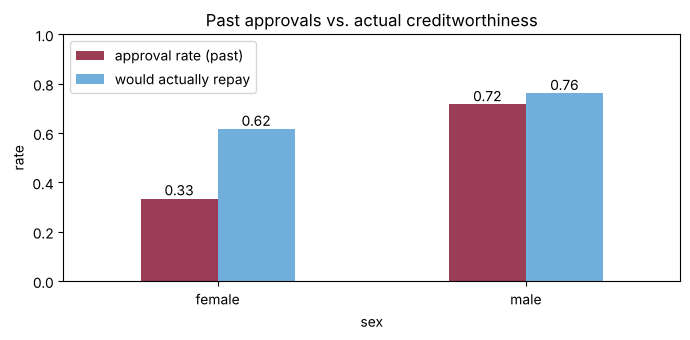

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
summary[["approval rate (past)", "would actually repay"]].plot.bar(ax=ax, color=["#9A3D55", "#70AFDC"], rot=0)
ax.set_ylabel("rate"); ax.set_ylim(0, 1); ax.set_title("Past approvals vs. actual creditworthiness")
for c in ax.containers: ax.bar_label(c, fmt="%.2f")
plt.tight_layout(); plt.show()

🗝 **Key observation 1.** Look at the two pairs of bars.

- In reality, women repay **slightly less often** than men (≈ 62% vs. 76%). This is not because of their sex: it is because the pay gap and part-time work
  give them lower incomes on average (historical bias).
- In the past, however, women were approved **much less often** than men (≈ 34% vs. 72%). The gap in approvals is far larger than the gap in actual repayment.

That *extra* gap is the loan officers' prejudice. And it is now written into the `approved` column, the labels our model is going to learn from.

## 2. Splitting the data and measuring bias *in the data*

### Three splits, not two

We split the data into three parts:

- **training set (60%)**: used to train the models;
- **validation set (20%)**: used to *tune* things, in particular the post-processing algorithm in Section 6.3, which must learn its thresholds on data that the model has not seen;
- **test set (20%)**: used **only** for the final evaluation.

We stratify on both the label and the sex, so that all three splits contain the same proportions of approved/rejected men and women.

We also keep `would_repay` **out of the features**: it is the ground truth, which a real bank would never have at decision time. We will only use it at the very end.

In [ ]:
FEATURES = ["sex", "age", "education_years", "part_time", "years_employed", "income", "debt_ratio", "previous_defaults"]
LABEL = "approved"

strat = df["approved"].astype(str) + "_" + df["sex"].astype(str)
train_df, temp_df = train_test_split(df, test_size=0.4, stratify=strat, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=strat.loc[temp_df.index], random_state=SEED)

# Standardise the numerical features (fit on training data only, to avoid leakage)
NUMERIC = [f for f in FEATURES if f != "sex"]
scaler = StandardScaler().fit(train_df[NUMERIC])
def prepare(d):
    out = d[FEATURES + [LABEL]].copy()
    out[NUMERIC] = scaler.transform(d[NUMERIC])
    return out

train, val, test = prepare(train_df), prepare(val_df), prepare(test_df)
truth_test = test_df["would_repay"].values      # kept aside for Section 8
print(f"train: {len(train)}  |  validation: {len(val)}  |  test: {len(test)}")

train: 12000  |  validation: 4000  |  test: 4000


### From pandas to AIF360: the `BinaryLabelDataset`

AIF360 does not work directly on pandas DataFrames. Every dataset must be wrapped in a **`BinaryLabelDataset`**, an object that knows:

- which column is the **label** (`label_names`) and which label value is **favorable** (`favorable_label`). Here, being approved (`1`) is the favorable outcome.
  *Careful:* in datasets like COMPAS the favorable outcome is `0` (not being predicted as a re-offender). Getting this wrong silently flips the sign of every metric!
- which column is the **protected attribute** (`protected_attribute_names`) and which value is **privileged** (`privileged_protected_attributes`).

We also define the two groups as lists of dictionaries. This format looks odd, but it allows AIF360 to handle intersections (e.g., `[{'sex': 0, 'race': 0}]`).

In [ ]:
PRIVILEGED = [{"sex": 1}]     # men
UNPRIVILEGED = [{"sex": 0}]   # women

def to_aif(d, labels=None, scores=None):
    # Wrap a DataFrame (features + label) into an AIF360 BinaryLabelDataset.
    # If `labels` is given, it replaces the label column (used to store a model's predictions).
    d = d.copy()
    if labels is not None:
        d[LABEL] = np.asarray(labels)
    ds = BinaryLabelDataset(df=d, label_names=[LABEL], protected_attribute_names=["sex"],
                            favorable_label=1, unfavorable_label=0,
                            privileged_protected_attributes=[[1]])
    if scores is not None:
        ds.scores = np.asarray(scores).reshape(-1, 1)
    return ds

aif_train = to_aif(train)

# What AIF360 stores inside the object:
print("label column        :", aif_train.label_names)
print("protected attribute :", aif_train.protected_attribute_names)
print("favorable label     :", aif_train.favorable_label)
print("instance weights    :", np.unique(aif_train.instance_weights), "(all 1 for now: remember this for Section 6.1)")
aif_train.convert_to_dataframe()[0].head()     # we can always convert back to pandas

label column        : ['approved']
protected attribute : ['sex']
favorable label     : 1.0
instance weights    : [1.] (all 1 for now: remember this for Section 6.1)


,sex,age,education_years,part_time,years_employed,income,debt_ratio,previous_defaults,approved
924,1.0,-1.207,0.995,-0.547,-1.212,0.761,-0.651,-0.549,1.0
16901,0.0,-1.207,1.796,-0.547,-0.273,0.645,2.350,-0.549,0.0
12385,1.0,1.688,0.194,-0.547,-0.912,-0.062,1.850,3.059,0.0
18764,0.0,-1.441,-2.209,1.830,-0.413,-1.583,-0.901,1.255,0.0
10886,1.0,-0.111,-0.607,-0.547,0.267,0.626,0.849,1.255,0.0


### Is the *data* already biased?

Before training any model we can already ask: **are the labels themselves distributed unfairly?** AIF360's `BinaryLabelDatasetMetric` answers this question.
It only looks at the labels in the dataset, not at any model.

- **Statistical Parity Difference** (SPD) $= P(Y=1 \mid \text{female}) - P(Y=1 \mid \text{male})$. 0 means equal approval rates; negative means women are approved less.
- **Disparate Impact** (DI) $= P(Y=1 \mid \text{female}) \, / \, P(Y=1 \mid \text{male})$. 1 means equal rates. Below **0.8** is the classic red flag (the US *four-fifths rule*).

In [ ]:
data_metric = BinaryLabelDatasetMetric(aif_train, unprivileged_groups=UNPRIVILEGED, privileged_groups=PRIVILEGED)
print(f"Approval rate, women: {data_metric.base_rate(privileged=False):.3f}")
print(f"Approval rate, men:   {data_metric.base_rate(privileged=True):.3f}")
print(f"Statistical Parity Difference: {data_metric.statistical_parity_difference():.3f}")
print(f"Disparate Impact:              {data_metric.disparate_impact():.3f}")

Approval rate, women: 0.335
Approval rate, men:   0.716
Statistical Parity Difference: -0.382
Disparate Impact:              0.467


🗝 **Key observation 2.** The training labels are heavily skewed: women were approved at less than half the rate of men (DI ≈ 0.47).
**Any model that learns these labels well will learn this skew too.** This is the *"garbage in, garbage out"* of fairness: a model can be no fairer than
the labels it is trained to imitate, unless we do something about it.

## 3. Baseline: three common ML models

We now train three classic classifiers **without any fairness intervention**, exactly as a team focused only on accuracy would do:

- **Logistic Regression**: a linear model. Simple, fast, interpretable: it learns one weight per feature.
- **Decision Tree** (max depth 6): a set of if-then rules learned from the data.
- **Random Forest** (200 trees): an ensemble of trees. Usually more accurate, but slower and much harder to interpret.

The models see all features, **including `sex`**.

In [ ]:
X_train, y_train = train[FEATURES], train[LABEL].values
X_val,   y_val   = val[FEATURES],   val[LABEL].values
X_test,  y_test  = test[FEATURES],  test[LABEL].values
sex_test = test["sex"].values

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=SEED, n_jobs=-1),
}
preds, fit_times = {}, {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_times[name] = time.perf_counter() - t0
    preds[name] = model.predict(X_test)
    print(f"{name:20s}  accuracy = {accuracy_score(y_test, preds[name]):.3f}   F1 = {f1_score(y_test, preds[name]):.3f}   "
          f"(trained in {fit_times[name]:.2f}s)")

Logistic Regression   accuracy = 0.841   F1 = 0.851   (trained in 0.01s)
Decision Tree         accuracy = 0.814   F1 = 0.825   (trained in 0.02s)


Random Forest         accuracy = 0.836   F1 = 0.847   (trained in 0.73s)


All three models reach an accuracy above 80%: they are good at reproducing the officers' decisions.
If we stopped here, a standard ML pipeline would happily ship the Logistic Regression. But accuracy only tells us **how well we imitate the past**.
It says nothing about **who pays the price for the errors**. Let's measure that.

## 4. Measuring fairness

### 4.1 The metrics, by hand

We use the four group-fairness metrics from the slides. In all of them, $u$ is the unprivileged group (women), $p$ the privileged group (men),
$\hat Y$ is the model's prediction and $Y$ the true label.

| Metric | Formula | Fair value | Question it answers |
|---|---|---|---|
| **Statistical Parity Difference** (SPD) | $P(\hat Y=1 \mid u) - P(\hat Y=1 \mid p)$ | 0 | Do both groups get approved at the same rate? |
| **Disparate Impact** (DI) | $P(\hat Y=1 \mid u) \, / \, P(\hat Y=1 \mid p)$ | 1 (≥ 0.8 acceptable) | Same question, as a ratio |
| **Equal Opportunity Difference** (EOD) | $TPR_u - TPR_p$ | 0 | Among people who *deserve* approval, are both groups approved equally? |
| **Average Odds Difference** (AOD) | $\tfrac12[(FPR_u - FPR_p) + (TPR_u - TPR_p)]$ | 0 | Are *both* kinds of errors balanced across groups? |

Note the difference between the first two and the last two:

- **SPD and DI** only look at the *predictions*. They ignore whether people deserved approval. This is the idea of **demographic parity**.
- **EOD and AOD** compare predictions with the *true labels* through the true positive rate (TPR) and false positive rate (FPR). This is the idea of **equal error rates**.

Before using a toolkit, let's implement them ourselves. It takes ten lines, and it removes any "magic" from what the toolkit does.

In [ ]:
def fairness_by_hand(y_true, y_pred, sex):
    y_true, y_pred, sex = map(np.asarray, (y_true, y_pred, sex))
    p, u = sex == 1, sex == 0                               # privileged (men), unprivileged (women)
    sel = lambda g: y_pred[g].mean()                        # selection (approval) rate
    tpr = lambda g: y_pred[g & (y_true == 1)].mean()        # true positive rate
    fpr = lambda g: y_pred[g & (y_true == 0)].mean()        # false positive rate
    return {"SPD": sel(u) - sel(p),
            "DI":  sel(u) / sel(p),
            "EOD": tpr(u) - tpr(p),
            "AOD": 0.5 * ((fpr(u) - fpr(p)) + (tpr(u) - tpr(p)))}

pd.Series(fairness_by_hand(y_test, preds["Logistic Regression"], sex_test), name="Logistic Regression (by hand)").to_frame().T

,SPD,DI,EOD,AOD
Logistic Regression (by hand),-0.461,0.398,-0.219,-0.237


### 4.2 The same metrics with AIF360: `ClassificationMetric`

To evaluate a **classifier**, AIF360 needs **two** datasets with the same rows and features:

1. the **original** test set, with the true labels;
2. a **copy** in which the label column contains the model's **predictions**.

`ClassificationMetric` compares the two, row by row, and computes the confusion matrix of each group. From there it can derive dozens of metrics.

In [ ]:
aif_test = to_aif(test)                                               # true labels
aif_test_pred = to_aif(test, labels=preds["Logistic Regression"])     # same rows, predicted labels

cm = ClassificationMetric(aif_test, aif_test_pred, unprivileged_groups=UNPRIVILEGED, privileged_groups=PRIVILEGED)

print(f"Statistical Parity Difference : {cm.statistical_parity_difference():.3f}")
print(f"Disparate Impact              : {cm.disparate_impact():.3f}")
print(f"Equal Opportunity Difference  : {cm.equal_opportunity_difference():.3f}")
print(f"Average Odds Difference       : {cm.average_odds_difference():.3f}")

Statistical Parity Difference : -0.461
Disparate Impact              : 0.398
Equal Opportunity Difference  : -0.219
Average Odds Difference       : -0.237


The numbers are **identical** to our hand-made version. Good: now we know exactly what the toolkit computes.

AIF360 can also give us the raw ingredients per group. These are often more informative than a single summary number, because they show
*which* error is unbalanced.

,women,men
approval rate,0.305,0.766
TPR (deserving people approved),0.709,0.928
FPR (undeserving people approved),0.101,0.357
accuracy,0.835,0.847


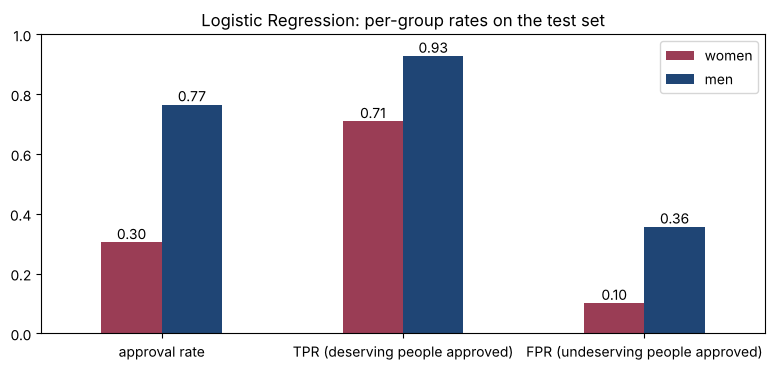

In [ ]:
per_group = pd.DataFrame({
    g: {"approval rate": cm.selection_rate(privileged=priv),
        "TPR (deserving people approved)": cm.true_positive_rate(privileged=priv),
        "FPR (undeserving people approved)": cm.false_positive_rate(privileged=priv),
        "accuracy": cm.accuracy(privileged=priv)}
    for g, priv in [("women", False), ("men", True)]})
display(per_group)

ax = per_group.iloc[:3].plot.bar(rot=0, figsize=(8, 3.8), color=["#9A3D55", "#1F4575"])
ax.set_ylim(0, 1); ax.set_title("Logistic Regression: per-group rates on the test set")
for c in ax.containers: ax.bar_label(c, fmt="%.2f")
plt.tight_layout(); plt.show()

🗝 **Key observation 3.** Read the chart group by group.

- **Approval rate.** Men are approved more than twice as often as women. That is SPD ≈ −0.46 and DI ≈ 0.40, far below the 0.8 threshold.
- **TPR.** Among applicants the officers *would have approved*, the model approves ≈ 93% of men but only ≈ 71% of women (EOD ≈ −0.22).
- **FPR.** Among applicants the officers *would have rejected*, men still get through much more often. So men benefit from the model's mistakes, women don't.
- **Accuracy** is almost the same for both groups. **A model can be equally accurate for two groups and still be very unfair to one of them.**
  This is why "it works equally well for everyone" is not a fairness argument.

### 4.3 A reusable evaluation function

From now on we evaluate many models, so we wrap everything in a single function. It returns accuracy, F1 and the four fairness metrics, all computed with AIF360.

In [ ]:
def evaluate(name, y_pred, fit_time=np.nan, ref=test, y_true=None):
    ref = ref.copy()
    if y_true is not None:
        ref[LABEL] = y_true
    m = ClassificationMetric(to_aif(ref), to_aif(ref, labels=y_pred),
                             unprivileged_groups=UNPRIVILEGED, privileged_groups=PRIVILEGED)
    return {"approach": name,
            "accuracy": m.accuracy(),
            "F1": f1_score(ref[LABEL], y_pred),
            "SPD": m.statistical_parity_difference(),
            "DI": m.disparate_impact(),
            "EOD": m.equal_opportunity_difference(),
            "AOD": m.average_odds_difference(),
            "fit time (s)": fit_time}

baseline = pd.DataFrame([evaluate(n, preds[n], fit_times[n]) for n in models]).set_index("approach")
baseline

,accuracy,F1,SPD,DI,EOD,AOD,fit time (s)
approach,,,,,,,
Logistic Regression,0.841,0.851,-0.461,0.398,-0.219,-0.237,0.011
Decision Tree,0.814,0.825,-0.419,0.438,-0.187,-0.212,0.020
Random Forest,0.836,0.847,-0.477,0.389,-0.232,-0.261,0.729


🗝 **Key observation 4.** All three models are clearly unfair towards women, on **all four** metrics.
Notice that the most complex model, the Random Forest, is **not** fairer than the simple ones. If anything, it is better at learning the patterns in the
data, *including the biased ones*. More model capacity means more faithful imitation of the labels, for better or worse.

## 5. A tempting fix: *"Just remove the sex column!"*

The most intuitive reaction to the results above is: *if the model discriminates by sex, let's not tell it the sex.*
This idea has a name: **fairness through unawareness**. It is also what many companies actually do, often for legal reasons.

Let's try it: we retrain the same three models **without** the `sex` feature. We still *evaluate* fairness by sex, of course.

In [ ]:
UNAWARE = [f for f in FEATURES if f != "sex"]
unaware_rows = []
for name, model in models.items():
    m = type(model)(**model.get_params())
    t0 = time.perf_counter(); m.fit(X_train[UNAWARE], y_train); t = time.perf_counter() - t0
    unaware_rows.append(evaluate(f"{name} (no sex)", m.predict(X_test[UNAWARE]), t))

pd.concat([baseline, pd.DataFrame(unaware_rows).set_index("approach")])

,accuracy,F1,SPD,DI,EOD,AOD,fit time (s)
approach,,,,,,,
Logistic Regression,0.841,0.851,-0.461,0.398,-0.219,-0.237,0.011
Decision Tree,0.814,0.825,-0.419,0.438,-0.187,-0.212,0.020
Random Forest,0.836,0.847,-0.477,0.389,-0.232,-0.261,0.729
Logistic Regression (no sex),0.825,0.835,-0.312,0.549,-0.089,-0.075,0.011
Decision Tree (no sex),0.808,0.821,-0.289,0.578,-0.062,-0.065,0.020
Random Forest (no sex),0.824,0.835,-0.311,0.555,-0.084,-0.076,0.781


The bias **shrinks** (SPD goes from about −0.45 to about −0.3, and EOD/AOD drop considerably), but it **does not disappear**: DI is still well below 0.8.

Why? Because the other features still **know** who is a woman. Let's prove it with a small experiment: we train a "spy" model whose only job is to
**guess the sex** of an applicant from the supposedly neutral features.

Guessing sex from the 'neutral' features: ROC-AUC = 0.77   (0.5 = random guess, 1.0 = perfect)


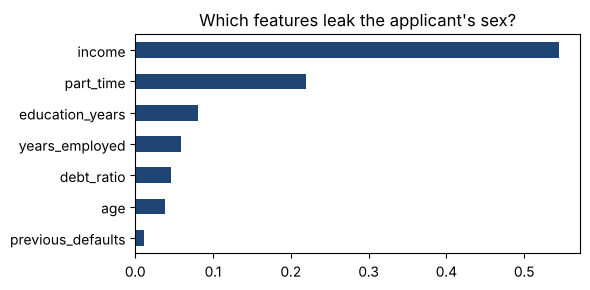

In [ ]:
spy = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=SEED, n_jobs=-1)
spy.fit(X_train[UNAWARE], X_train["sex"])
auc = roc_auc_score(X_test["sex"], spy.predict_proba(X_test[UNAWARE])[:, 1])
print(f"Guessing sex from the 'neutral' features: ROC-AUC = {auc:.2f}   (0.5 = random guess, 1.0 = perfect)")

imp = pd.Series(spy.feature_importances_, index=UNAWARE).sort_values()
ax = imp.plot.barh(figsize=(6, 3), color="#1F4575")
ax.set_title("Which features leak the applicant's sex?")
plt.tight_layout(); plt.show()

🗝 **Key observation 5.** The spy guesses sex far better than chance (ROC-AUC ≈ 0.77), mostly using `part_time` and `income`.
These are **proxy features**: removing the sensitive attribute does not remove the information; it just hides it.

Unawareness has an even worse side effect: if you delete the `sex` column from your data, **you can no longer measure** whether your system discriminates by sex.
You have made the problem invisible, not solved it.

💬 *Real-world proxies:* ZIP code ↔ ethnicity, first name ↔ gender, shopping habits ↔ age, gaps in a CV ↔ maternity leave.
Can you think of others?

## 6. Mitigating bias

We now try three **real** mitigation techniques, one for each stage of the ML pipeline, exactly as in the slides.
We always start from the **Logistic Regression** baseline, so that the comparison is fair.

| Stage | Algorithm (AIF360 class) | What it changes | Reference |
|---|---|---|---|
| **Pre**-processing | `Reweighing` | the **data**: gives each training example a weight | Kamiran & Calders, 2012 |
| **In**-processing | `PrejudiceRemover` | the **training**: adds a fairness penalty to the loss function | Kamishima et al., 2012 |
| **Post**-processing | `EqOddsPostprocessing` | the **decisions**: changes the model's output for some individuals | Hardt et al., 2016 |

For each technique we record accuracy, F1, the four fairness metrics, and the **training time**, which we will use as a rough proxy for computational
(and therefore energy) cost.

In [ ]:
results = [evaluate("Baseline (LogReg)", preds["Logistic Regression"], fit_times["Logistic Regression"])]

### 6.1 Pre-processing: Reweighing

**Idea.** The problem in our training data is that *sex* and *label* are statistically dependent: being a woman makes you less likely to be approved.
Reweighing does not touch any feature value or label. It simply gives each training example a **weight**, chosen so that, in the *weighted* data,
sex and label become **independent**.

For an example with sex $a$ and label $y$, the weight is:

$$w(a, y) = \frac{P(A=a)\cdot P(Y=y)}{P(A=a,\ Y=y)}$$

- The numerator is how often the combination $(a, y)$ **would** appear if sex and label were independent.
- The denominator is how often it **actually** appears.

So combinations that are *rarer than they should be* (approved women, rejected men) get a weight **above 1**, and combinations that are
*more frequent than they should be* (rejected women, approved men) get a weight **below 1**.

Let's first compute the weights by hand, then compare them with AIF360.

In [ ]:
d = pd.DataFrame({"sex": train["sex"], "y": y_train})
p_a = d["sex"].value_counts(normalize=True)
p_y = d["y"].value_counts(normalize=True)
p_ay = d.groupby(["sex", "y"]).size() / len(d)
hand_w = pd.Series({(a, y): p_a[a] * p_y[y] / p_ay[(a, y)] for (a, y) in p_ay.index}, name="weight (by hand)")
hand_w.index = pd.MultiIndex.from_tuples([(SEX_NAMES[a], y) for a, y in hand_w.index], names=["sex", "approved"])
hand_w.to_frame()

weight (by hand)
sex    approved                  
female 0                    0.711
       1                    1.574
male   0                    1.668
       1                    0.735

In [ ]:
RW = Reweighing(unprivileged_groups=UNPRIVILEGED, privileged_groups=PRIVILEGED)
aif_train_rw = RW.fit_transform(aif_train)
weights = aif_train_rw.instance_weights

check = (pd.DataFrame({"sex": train["sex"].map(SEX_NAMES).values, "approved": y_train, "weight (AIF360)": weights})
           .groupby(["sex", "approved"])["weight (AIF360)"].first())
pd.concat([hand_w, check], axis=1)

weight (by hand)  weight (AIF360)
sex    approved                                   
female 0                    0.711            0.711
       1                    1.574            1.574
male   0                    1.668            1.668
       1                    0.735            0.735

Same weights. Now let's verify that, **in the weighted training set**, the bias in the labels is gone. `BinaryLabelDatasetMetric` automatically takes the instance weights into account:

In [ ]:
m_before = BinaryLabelDatasetMetric(aif_train, unprivileged_groups=UNPRIVILEGED, privileged_groups=PRIVILEGED)
m_after = BinaryLabelDatasetMetric(aif_train_rw, unprivileged_groups=UNPRIVILEGED, privileged_groups=PRIVILEGED)
print(f"SPD of the training labels  before reweighing: {m_before.statistical_parity_difference():.3f}")
print(f"SPD of the training labels  after  reweighing: {m_after.statistical_parity_difference():.3f}")

SPD of the training labels  before reweighing: -0.382
SPD of the training labels  after  reweighing: -0.000


In the weighted data, women and men have **exactly the same** approval rate. We now train the same Logistic Regression, passing the weights through
scikit-learn's `sample_weight` argument. Any model that accepts `sample_weight` can be used: this is the big advantage of pre-processing.

In [ ]:
lr_rw = LogisticRegression(max_iter=1000)
t0 = time.perf_counter();
lr_rw.fit(X_train, y_train, sample_weight=weights);
t = time.perf_counter() - t0
pred_rw = lr_rw.predict(X_test)
results.append(evaluate("Pre: Reweighing", pred_rw, t))
pd.DataFrame(results).set_index("approach")

,accuracy,F1,SPD,DI,EOD,AOD,fit time (s)
approach,,,,,,,
Baseline (LogReg),0.841,0.851,-0.461,0.398,-0.219,-0.237,0.011
Pre: Reweighing,0.816,0.827,-0.246,0.627,-0.017,-0.006,0.012


🗝 **Key observation 6.** With a change that took one line of code and *no* extra training time, SPD is roughly **halved** and DI goes up substantially.
EOD and AOD drop to about **zero**: deserving women and deserving men (according to the labels) are now approved at the same rate.
The price is a couple of accuracy points with respect to the past decisions.

Note that SPD is **not** zero, even though the weighted training labels were perfectly balanced. Why? Because the model still sees `income` and `part_time`,
which genuinely differ between groups. Reweighing removes the dependency between sex and *label*, not between sex and the *features*.

### 6.2 In-processing: Prejudice Remover

**Idea.** Instead of changing the data, we change **what the model optimises**. A normal Logistic Regression minimises the prediction error (log-loss).
The **Prejudice Remover** adds a second term to the loss, a *prejudice index*, which measures how much information the predictions carry about the sensitive attribute
(technically, the mutual information between $\hat Y$ and sex):

$$\text{loss} = \underbrace{\text{prediction error}}_{\text{accuracy}} \; + \; \eta \cdot \underbrace{\text{prejudice index}}_{\text{fairness}} \; + \; \text{regularisation}$$

The hyper-parameter **$\eta$ (eta)** controls the trade-off:

- $\eta = 0$ → a plain Logistic Regression;
- larger $\eta$ → the model is pushed harder to make predictions that do not depend on sex, at the cost of accuracy.

This is the essence of in-processing: **fairness becomes part of the objective function**. Unlike Reweighing, it is tied to a specific model family (here, logistic regression),
and you need to modify the learning algorithm itself.

AIF360's `PrejudiceRemover` works directly on `BinaryLabelDataset`s. Let's train it with $\eta = 25$:

> *Technical note:* AIF360 runs the Prejudice Remover in a separate Python process, so our warning filters do not reach it. Depending on your scikit-learn version you may see a few  messages here: they are harmless.

In [ ]:
aif_test = to_aif(test)
pr = PrejudiceRemover(eta=25.0, sensitive_attr="sex", class_attr=LABEL)
t0 = time.perf_counter(); pr.fit(aif_train); t = time.perf_counter() - t0
pred_pr = pr.predict(aif_test).labels.ravel().astype(int)
results.append(evaluate("In: Prejudice Remover (eta=25)", pred_pr, t))
pd.DataFrame(results).set_index("approach")

,accuracy,F1,SPD,DI,EOD,AOD,fit time (s)
approach,,,,,,,
Baseline (LogReg),0.841,0.851,-0.461,0.398,-0.219,-0.237,0.011
Pre: Reweighing,0.816,0.827,-0.246,0.627,-0.017,-0.006,0.012
In: Prejudice Remover (eta=25),0.709,0.730,-0.102,0.831,0.040,0.066,9.960


Since $\eta$ is a knob, let's turn it and **see the trade-off** with our own eyes. We train the Prejudice Remover for several values of $\eta$ and plot
accuracy and |SPD| for each. *(This cell takes 1–2 minutes: it trains seven models, and the Prejudice Remover is slow. While it runs, ask yourself why.)*

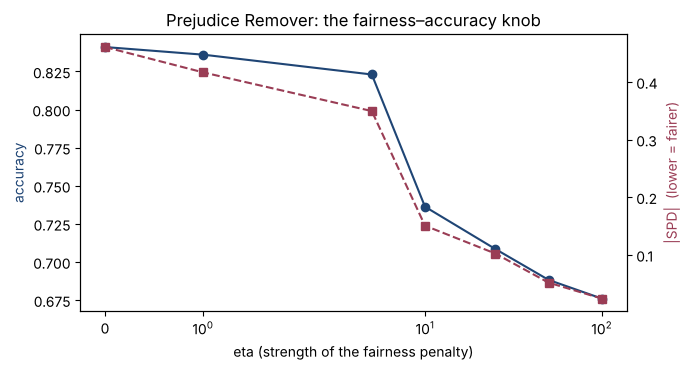

,accuracy,SPD,DI,EOD
eta,,,,
0,0.841,-0.461,0.397,-0.218
1,0.836,-0.417,0.439,-0.170
5,0.823,-0.349,0.512,-0.117
10,0.736,-0.151,0.766,-0.008
25,0.709,-0.102,0.831,0.040
50,0.688,-0.052,0.911,0.077
100,0.676,-0.024,0.958,0.085


In [ ]:
etas = [0, 1, 5, 10, 25, 50, 100]
sweep = []
for eta in etas:
    m = PrejudiceRemover(eta=float(eta), sensitive_attr="sex", class_attr=LABEL).fit(aif_train)
    p = m.predict(aif_test).labels.ravel().astype(int)
    r = evaluate(f"eta={eta}", p); r["eta"] = eta
    sweep.append(r)
sweep = pd.DataFrame(sweep)

fig, ax1 = plt.subplots(figsize=(7, 3.8))
ax1.plot(sweep["eta"], sweep["accuracy"], "o-", color="#1F4575", label="accuracy")
ax1.set_xlabel("eta (strength of the fairness penalty)"); ax1.set_ylabel("accuracy", color="#1F4575")
ax2 = ax1.twinx()
ax2.plot(sweep["eta"], sweep["SPD"].abs(), "s--", color="#9A3D55", label="|SPD|")
ax2.set_ylabel("|SPD|  (lower = fairer)", color="#9A3D55")
ax1.set_xscale("symlog"); ax1.set_title("Prejudice Remover: the fairness–accuracy knob")
plt.tight_layout(); plt.show()
sweep[["eta", "accuracy", "SPD", "DI", "EOD"]].set_index("eta")

🗝 **Key observation 7.** As $\eta$ grows, |SPD| goes down and accuracy goes down with it. There is no "free" point: **every** value of $\eta$ is a different compromise.
Notice also that the curve is not smooth: between $\eta = 5$ and $\eta = 10$ the model suddenly changes behaviour, gaining a lot of fairness and losing a lot of accuracy.
Fairness hyper-parameters need to be **explored**, not guessed.

With $\eta = 25$ (our run in the previous cell) DI goes above 0.8 for the first time, but the model has lost more than 10 accuracy points with respect to the past decisions.

Who should choose $\eta$? Not (only) the data scientist. The right value depends on the domain, on the law, and on how much accuracy the stakeholders are willing to trade
for fairness. This is a **requirements decision**, encoded as a hyper-parameter.

### 6.3 Post-processing: Equalized Odds

**Idea.** We keep the trained baseline **untouched** and only adjust its **decisions**. `EqOddsPostprocessing` (Hardt et al., 2016) looks at the
baseline's predictions on the **validation set** and learns, for each group, a probability of **flipping** a prediction, so that both groups end up with the
same **true positive rate** *and* the same **false positive rate**. This target is called **Equalized Odds**.

Why the validation set? The post-processor must learn on data that the model has not been trained on, otherwise it would calibrate itself on overly optimistic predictions.
And it must not be the test set, otherwise we would be cheating in the final evaluation.

Two things to notice about post-processing:

- It works with **any** model, even a black box you bought from a vendor: you only need its predictions.
- It needs the **sensitive attribute at decision time**, because the flipping probabilities depend on the group. In some domains, using sex explicitly
  in a decision is itself illegal (*disparate treatment*).

In [ ]:
base_lr = models["Logistic Regression"]
aif_val = to_aif(val)
aif_val_pred = to_aif(val, labels=base_lr.predict(X_val))
aif_test_pred = to_aif(test, labels=preds["Logistic Regression"])

eqo = EqOddsPostprocessing(unprivileged_groups=UNPRIVILEGED, privileged_groups=PRIVILEGED, seed=SEED)
t0 = time.perf_counter(); eqo.fit(aif_val, aif_val_pred); t = time.perf_counter() - t0
pred_eo = eqo.predict(aif_test_pred).labels.ravel().astype(int)
results.append(evaluate("Post: Equalized Odds", pred_eo, t))
print(f"Decisions changed by the post-processor: {(pred_eo != preds['Logistic Regression']).sum()} out of {len(pred_eo)}")
pd.DataFrame(results).set_index("approach")

Decisions changed by the post-processor: 572 out of 4000


,accuracy,F1,SPD,DI,EOD,AOD,fit time (s)
approach,,,,,,,
Baseline (LogReg),0.841,0.851,-0.461,0.398,-0.219,-0.237,0.011
Pre: Reweighing,0.816,0.827,-0.246,0.627,-0.017,-0.006,0.012
In: Prejudice Remover (eta=25),0.709,0.730,-0.102,0.831,0.040,0.066,9.960
Post: Equalized Odds,0.743,0.759,-0.175,0.721,0.018,0.011,0.011


🗝 **Key observation 8.** The post-processor changes about one decision in seven, and it brings **EOD and AOD close to zero**: its target is equal error rates.
But SPD stays clearly negative (≈ −0.18): equal *error rates* do not imply equal *approval rates*, because the groups have different base rates in the labels.
Flipping decisions at random within a group is also costly: accuracy drops by about 10 points.
Different techniques optimise **different definitions of fairness**: remember the impossibility theorem from the slides.

💬 *Is it acceptable that two applicants with identical features receive different decisions because of their sex?* That is exactly what group-specific post-processing does.

## 7. Trade-offs: accuracy vs. fairness vs. cost

Let's put everything together.

In [ ]:
res = pd.DataFrame(results).set_index("approach")
res

,accuracy,F1,SPD,DI,EOD,AOD,fit time (s)
approach,,,,,,,
Baseline (LogReg),0.841,0.851,-0.461,0.398,-0.219,-0.237,0.011
Pre: Reweighing,0.816,0.827,-0.246,0.627,-0.017,-0.006,0.012
In: Prejudice Remover (eta=25),0.709,0.730,-0.102,0.831,0.040,0.066,9.960
Post: Equalized Odds,0.743,0.759,-0.175,0.721,0.018,0.011,0.011


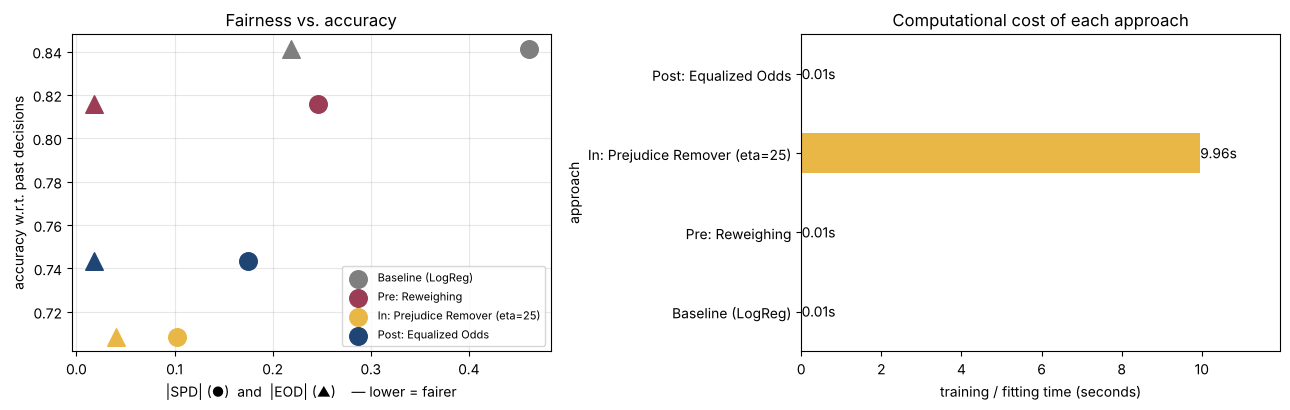

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
colors = ["#7F7F7F", "#9A3D55", "#E9B746", "#1F4575"]

ax = axes[0]
for (name, r), c in zip(res.iterrows(), colors):
    ax.scatter(abs(r["SPD"]), r["accuracy"], s=160, color=c, label=name, zorder=3)
    ax.scatter(abs(r["EOD"]), r["accuracy"], s=160, color=c, marker="^", zorder=3)
ax.set_xlabel("|SPD| (●)  and  |EOD| (▲)    — lower = fairer"); ax.set_ylabel("accuracy w.r.t. past decisions")
ax.set_title("Fairness vs. accuracy"); ax.grid(alpha=.3); ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
res["fit time (s)"].plot.barh(ax=ax, color=colors)
ax.set_xlim(0, res["fit time (s)"].max() * 1.2)
ax.set_xlabel("training / fitting time (seconds)"); ax.set_title("Computational cost of each approach")
for c in ax.containers: ax.bar_label(c, fmt="%.2fs")
plt.tight_layout(); plt.show()

🗝 **Key observation 9.** Three lessons from these two charts.

1. **Every technique reduces bias**, but on **different metrics**: Prejudice Remover attacks SPD (equal approval rates), Equalized Odds post-processing attacks EOD (equal error rates),
   and Reweighing sits in between. *Which* fairness you get depends on *which* technique you choose, so the technique must follow the requirement, not the other way round.
2. **Accuracy with respect to past decisions goes down.** That is expected: we are deliberately *disagreeing* with biased officers.
3. **Costs differ a lot.** Reweighing and post-processing are practically free (hundredths of a second). The Prejudice Remover takes **seconds**: hundreds of times
   more than the baseline, because it solves a harder optimisation problem with a custom optimiser.
   (Exact timings depend on the machine, but the ranking is stable.) In a real system trained daily on millions of rows, that difference becomes **energy, money and CO₂**.
   This is the sustainability trade-off we discussed in the lecture: social sustainability (fairness) can compete with environmental and economic sustainability.

### Does Reweighing work for every model?

Pre-processing is **model-agnostic**: the same weights can be given to any estimator that accepts `sample_weight`. Let's apply them to all three baselines.

In [ ]:
rows = []
for name, model in models.items():
    m = type(model)(**model.get_params())
    m.fit(X_train, y_train, sample_weight=weights)
    before, after = evaluate(name, preds[name]), evaluate(name, m.predict(X_test))
    rows.append({"model": name,
                 "accuracy before": before["accuracy"], "accuracy after": after["accuracy"],
                 "SPD before": before["SPD"], "SPD after": after["SPD"],
                 "DI before": before["DI"], "DI after": after["DI"],
                 "EOD before": before["EOD"], "EOD after": after["EOD"]})
pd.DataFrame(rows).set_index("model")

,accuracy before,accuracy after,SPD before,SPD after,DI before,DI after,EOD before,EOD after
model,,,,,,,,
Logistic Regression,0.841,0.816,-0.461,-0.246,0.398,0.627,-0.219,-0.017
Decision Tree,0.814,0.800,-0.419,-0.273,0.438,0.609,-0.187,-0.039
Random Forest,0.836,0.820,-0.477,-0.264,0.389,0.605,-0.232,-0.035


The same pattern holds for all three models: substantially less bias for a small accuracy cost, with no change to the models themselves.
This is one of the reasons why pre-processing techniques are popular in practice: they fit into an existing pipeline without touching the training code.

## 8. Plot twist: who is actually right?

So far, every accuracy and every EOD/AOD value was computed against `approved`, i.e., against **what the biased officers decided**.
Think about what that means: a model that perfectly reproduces the officers' prejudice gets a **perfect score**.

Because our data is simulated, we can do something real projects can't: re-evaluate every approach against `would_repay`, the **ground truth** of who would really have paid back the loan.

In [ ]:
named_preds = {"Baseline (LogReg)": preds["Logistic Regression"], "Pre: Reweighing": pred_rw,
               "In: Prejudice Remover (eta=25)": pred_pr, "Post: Equalized Odds": pred_eo}
truth = pd.DataFrame([evaluate(n, p, y_true=truth_test) for n, p in named_preds.items()]).set_index("approach")
comparison = pd.concat([res[["accuracy", "EOD"]].add_suffix(" (vs. past decisions)"),
                        truth[["accuracy", "EOD"]].add_suffix(" (vs. truth)")], axis=1)
comparison

,accuracy (vs. past decisions),EOD (vs. past decisions),accuracy (vs. truth),EOD (vs. truth)
approach,,,,
Baseline (LogReg),0.841,-0.219,0.684,-0.420
Pre: Reweighing,0.816,-0.017,0.682,-0.206
In: Prejudice Remover (eta=25),0.709,0.040,0.653,-0.065
Post: Equalized Odds,0.743,0.018,0.647,-0.146


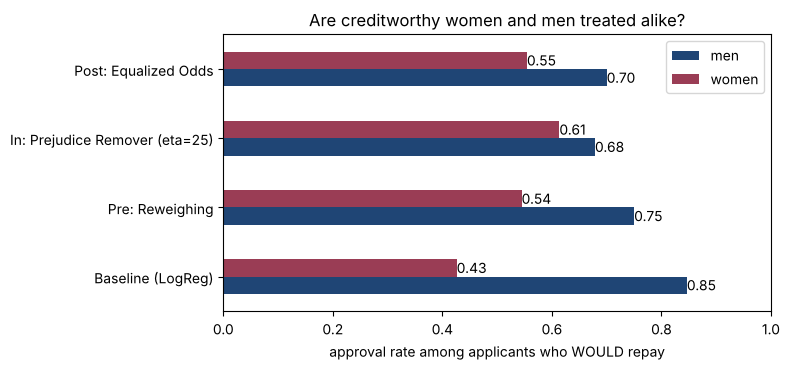

In [ ]:
creditworthy = truth_test == 1
rate = {n: {"men": p[creditworthy & (sex_test == 1)].mean(), "women": p[creditworthy & (sex_test == 0)].mean()}
        for n, p in named_preds.items()}
ax = pd.DataFrame(rate).T.plot.barh(figsize=(8, 3.8), color=["#1F4575", "#9A3D55"])
ax.set_xlim(0, 1); ax.set_xlabel("approval rate among applicants who WOULD repay")
ax.set_title("Are creditworthy women and men treated alike?")
for c in ax.containers: ax.bar_label(c, fmt="%.2f")
plt.tight_layout(); plt.show()

🗝 **Key observation 10.** Compare the two halves of the table.

- **Against the past decisions**, the baseline looks like the best model by a clear margin.
- **Against the truth**, the accuracy differences between approaches **shrink a lot**: from up to ≈ 13 points to at most ≈ 4. Reweighing is now practically as accurate as
  the baseline (0.682 vs. 0.684). Much of the "accuracy cost" of fairness was an artefact of measuring against biased labels.
- Against the truth, the fairest model is the **Prejudice Remover** (EOD ≈ −0.07, vs. −0.42 for the baseline): the technique that looked worst on accuracy is the one that
  treats creditworthy women and men most alike.
- The chart shows what the baseline was really doing: it approves a large majority of creditworthy men but **less than half of creditworthy women**.
  It was very good at imitating the officers, *prejudice included*.
- Look at **Equalized Odds post-processing**: against the past decisions its EOD was ≈ 0, so it looked perfectly fair. Against the truth it is still clearly unfair (EOD ≈ −0.15),
  because it equalised error rates **with respect to biased labels**. Being "fair" relative to a biased ground truth is not the same as being fair.

**Lesson for software engineers:** your **test set inherits the bias of your labels**. A model can pass every test and still be wrong in exactly the way
the past was wrong. Deciding *what to measure against*, and *where the labels come from*, is a requirements and data-engineering decision, not only an ML one.

💬 In real projects we never have `would_repay`. How could a bank get closer to it? (Hints: approving a random sample of borderline applications,
auditing old decisions, outcome data from other lenders, …) What are the risks and costs of each option?

## 9. Your turn 🧪

Try these on your own. Each one requires changing only a few lines.

1. **Turn the bias knob.** In `make_loan_data`, set the officers' penalty (`- 0.6 * female`) to `0` and re-run everything.
   Is the baseline still unfair? On which metrics? *(Hint: the pay gap and `part_time` are still there.)*
2. **Remove the pay gap too.** Set the `0.88` factor to `1.0`. What is left?
3. **Another post-processor.** Replace `EqOddsPostprocessing` with `RejectOptionClassification` from `aif360.algorithms.postprocessing`.
   It flips decisions only for applicants close to the decision boundary (the "critical region"). It needs predicted **scores**: use
   `to_aif(val, labels=..., scores=base_lr.predict_proba(X_val)[:, 1])`. Which metric does it improve?
4. **Another sensitive attribute.** Create an `age_group` column (`1` if age ≥ 30, else `0`) and measure fairness with respect to age (multi-attribute setting).
   Is the model biased against young applicants?
5. **Intersectionality.** AIF360 groups are lists of dictionaries. Define two attributes and measure fairness for *young women* vs. *older men*.
6. **Measure energy, not just time.** Install `codecarbon` (`!pip install codecarbon`) and wrap the `fit` calls in an `EmissionsTracker()` to estimate the
   CO₂ emitted by each mitigation technique.

---

### Take-home messages

- Fairness can be **measured** with a handful of metrics, but they encode **different ideas** of fairness (equal outcomes vs. equal error rates), and they can conflict.
- **Bias can be measured in the data itself**, before any model is trained.
- **Dropping the sensitive attribute is not enough**: proxies leak it back in, and you lose the ability to measure the problem.
- Mitigation can act on the **data** (pre), the **training** (in), or the **decisions** (post). Each targets a different fairness definition, has a different cost,
  and has different requirements (e.g., access to the sensitive attribute at decision time).
- If labels come from a biased past, **accuracy itself is a biased metric**.

### References

- Kamiran & Calders (2012). *Data preprocessing techniques for classification without discrimination.* Knowledge and Information Systems. *(Reweighing)*
- Kamishima, Akaho, Asoh & Sakuma (2012). *Fairness-aware classifier with prejudice remover regularizer.* ECML PKDD. *(Prejudice Remover)*
- Hardt, Price & Srebro (2016). *Equality of opportunity in supervised learning.* NeurIPS. *(Equalized Odds)*
- Bellamy et al. (2019). *AI Fairness 360: An extensible toolkit for detecting and mitigating algorithmic bias.* IBM Journal of Research and Development.
- AIF360 documentation: https://aif360.readthedocs.io